In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

PUE (1.5):  2463750.0
PUE (1.4):  2299500.0
PUE (1.3):  2135250.0
PUE (1.2):  1971000.0
PUE (1.1):  1806750.0000000002
Yearly: 


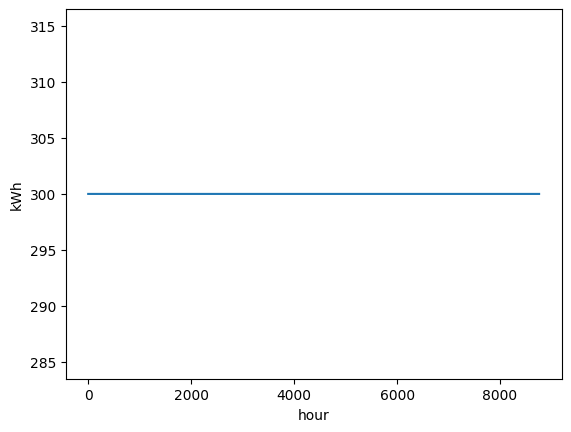

In [2]:
utilization_factor = 0.3
max_power = 1e3

average_hourly = max_power * utilization_factor
demand = np.ones(365 * 24) * average_hourly
sns.lineplot(demand)
plt.xlabel('hour')
plt.ylabel('kWh')

CURRENT_PUE = 1.6
pues = [1.5, 1.4, 1.3, 1.2, 1.1]

yearly_it = np.sum(demand) / CURRENT_PUE
for pue in pues:
  print(f'PUE ({pue}): ', (pue * yearly_it))


print("Yearly: ", )



In [3]:
def calc_price_psu(yearly_sum: float, price_per_kwh: float, max: float, min = 1.0, ):
  x = np.arange(min, max, 0.02)
  return   x, x * yearly_sum * price_per_kwh

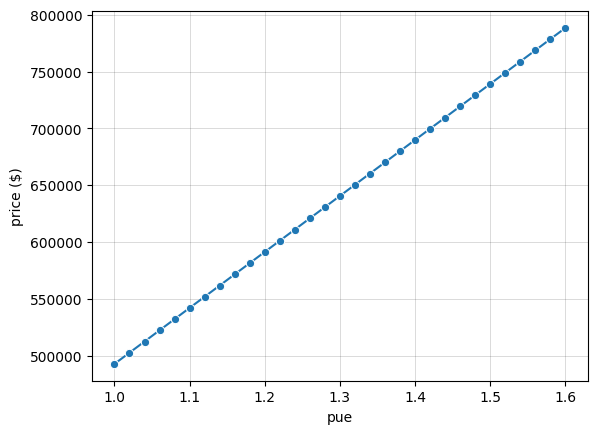

In [4]:
x, y = calc_price_psu(yearly_it, 0.3, 1.6)
sns.lineplot({'pue': x, 'price ($)': y}, x='pue', y='price ($)', marker='o')

# More precise grid with lower opacity
plt.grid(True, which='both', linestyle='-', linewidth=0.5, color='black', alpha=0.2)

In [5]:
def calc_demand(max_power: float, number_of_parallel_works: int, base_demand = 0.25, training_probability = 0.7, work_continuity = 0.15):
  year_hours = 365 * 24
  demand = np.ones(year_hours) * base_demand * max_power
  works_power_consumption = np.random.random(number_of_parallel_works)
  works_power_consumption /= sum(works_power_consumption)
  for w in range(number_of_parallel_works):
    is_training = np.random.random() < training_probability
    w_training_hours = np.zeros(year_hours, dtype=np.float32)
    for i in range(year_hours):
      probability = (1 + work_continuity) * training_probability if is_training else (1 - work_continuity) * training_probability
      # probability = training_probability
      if np.random.random() < probability:
        w_training_hours[i] = 1.0
    demand += w_training_hours * works_power_consumption[w] * (1.0 - base_demand) * max_power


  return demand


0.7241359408642871

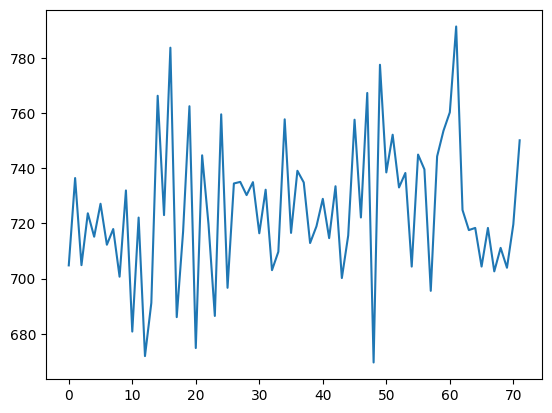

In [8]:
demand = calc_demand(10, 300, training_probability=0.6, work_continuity=0.2)
sns.lineplot(demand[:3 * 24])
np.sum(demand) / (365 * 24 * 1000)

In [7]:
np.random.random() < 10

True